In [1]:
import os
import numpy as np
from sklearn.model_selection import train_test_split
from torchvision.datasets import ImageFolder
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import cv2
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE

In [2]:
# Path to the directory containing one folder per class
data_dir = "/Users/gavinlee/Downloads/Processed Data"

# Read image paths and their class labels
dataset = ImageFolder(data_dir)

image_paths = np.array([path for path, label in dataset.samples])
labels = np.array([label for path, label in dataset.samples])

# Split off 30% for validation + test
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    image_paths,
    labels,
    test_size=0.30,
    random_state=34,
    stratify=labels
)

# Split the remaining 30% equally into validation and test
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths,
    temp_labels,
    test_size=0.50,
    random_state=34,
    stratify=temp_labels
)

print(f"Training images:   {len(train_paths)}")
print(f"Validation images: {len(val_paths)}")
print(f"Test images:       {len(test_paths)}")

Training images:   9912
Validation images: 2124
Test images:       2124


In [3]:
print("Class order:")

for index, class_name in enumerate(dataset.classes):
    print(f"{index}: {class_name}")

Class order:
0: Fresh Banana(1-4)
1: Fresh Bittermelon(1-3)
2: Fresh Cucumber(1-6)
3: Fresh Orange(1-9)
4: Fresh Papaya(1-4)
5: Fresh Tomato(1-10)
6: Fresh eggplant(1-4)
7: Fresh pineapple(1-15)
8: Rotten Bittermelon(5-8)
9: Rotten Cucumber(12-20)
10: Rotten Orange(20-35)
11: Rotten Papaya(7-12)
12: Rotten Pineapple(25-35)
13: Rotten Tomato(24-35)
14: Rotten banana(7-13)
15: Rotten eggplant(8-15)
16: Semi Fresh Bittermelon ( 3-5)
17: Semi Fresh Cucumber(6-12)
18: Semi Fresh Papaya(4-7)
19: Semi fresh Orange(9-20)
20: Semi fresh Pineapple (15-25)
21: Semi fresh Tomato(10-24)
22: Semi fresh banana(4-7)
23: Semi_Fresh eggplant(4-8)


In [4]:
# Get the class names from ImageFolder
class_names = dataset.classes

# Summarize each split
def summarize_split(name, split_labels):
    counts = np.bincount(split_labels, minlength=len(class_names))
    
    return pd.DataFrame({
        "Class": class_names,
        "Count": counts,
        "Split": name
    })

summary = pd.concat([
    summarize_split("Train", train_labels),
    summarize_split("Validation", val_labels),
    summarize_split("Test", test_labels)
], ignore_index=True)

# Display the results
print(summary.pivot(
    index="Class",
    columns="Split",
    values=["Count"]
))

                              Count                 
Split                          Test Train Validation
Class                                               
Fresh Banana(1-4)                88   413         89
Fresh Bittermelon(1-3)           89   413         88
Fresh Cucumber(1-6)              89   413         88
Fresh Orange(1-9)                89   413         88
Fresh Papaya(1-4)                89   413         88
Fresh Tomato(1-10)               89   413         88
Fresh eggplant(1-4)              88   413         89
Fresh pineapple(1-15)            88   413         89
Rotten Bittermelon(5-8)          88   413         89
Rotten Cucumber(12-20)           89   413         88
Rotten Orange(20-35)             89   413         88
Rotten Papaya(7-12)              89   413         88
Rotten Pineapple(25-35)          88   413         89
Rotten Tomato(24-35)             89   413         88
Rotten banana(7-13)              89   413         88
Rotten eggplant(8-15)            88   413     

1. Break into Train/Validation/Test
2. Apply Mask + Extract HSV Histogram
3. Apply to images to get feature vector
4. Visualize a example of each (fruit x freshness)
5. Visualize the distribution across the dataset
6. PCA
7. TSNE

In [5]:

def create_fruit_mask(image):

    h, w = image.shape[:2]

    # Smooth image
    smooth = cv2.GaussianBlur(image, (5, 5), 0)

    # Convert to LAB
    lab = cv2.cvtColor(smooth, cv2.COLOR_BGR2LAB).astype(np.float32)

    # Estimate background from image borders
    border = np.concatenate([
        lab[0, :, :],
        lab[-1, :, :],
        lab[:, 0, :],
        lab[:, -1, :]
    ])

    bg = np.median(border, axis=0)

    # Calculate color distance from background
    chroma = np.linalg.norm(lab[:, :, 1:] - bg[1:], axis=2)
    light = np.abs(lab[:, :, 0] - bg[0])

    dist = chroma + 0.25 * light

    # Normalize distance
    dist = cv2.normalize(
        dist, None, 0, 255, cv2.NORM_MINMAX
    ).astype(np.uint8)

    # Otsu thresholding
    _, mask = cv2.threshold(
        dist, 0, 255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    # Morphological operations
    kernel = np.ones((10, 10), np.uint8)

    # Remove small noise
    mask = cv2.morphologyEx(
        mask, cv2.MORPH_OPEN, kernel
    )

    # Close gaps between fruit regions
    mask = cv2.morphologyEx(
        mask, cv2.MORPH_CLOSE, kernel
    )

    # Find external contours
    contours, _ = cv2.findContours(
        mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    if contours:

        # Select largest contour
        largest = max(contours, key=cv2.contourArea)

        # Fill the entire fruit region
        fruit_mask = np.zeros((h, w), dtype=np.uint8)

        cv2.drawContours(
            fruit_mask, [largest], -1, 255, cv2.FILLED
        )

        # Expand the mask slightly to capture mold
        expand_kernel = np.ones((9, 9), np.uint8)

        fruit_mask = cv2.dilate(
            fruit_mask, expand_kernel, iterations=1
        )

        return fruit_mask

    return mask


In [6]:
# HSV Color Histogram with Fruit Mask

def extract_hsv_histogram(image_path):

    # Load image
    image = cv2.imread(image_path)

    # Generate intelligent fruit mask
    mask = create_fruit_mask(image)

    # Convert BGR to HSV
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

    # Calculate masked histogram for each channel
    h_hist = cv2.calcHist([hsv], [0], mask, [32], [0, 180])
    s_hist = cv2.calcHist([hsv], [1], mask, [32], [0, 256])
    v_hist = cv2.calcHist([hsv], [2], mask, [32], [0, 256])

    # Normalize histograms
    h_hist = cv2.normalize(h_hist, h_hist, norm_type=cv2.NORM_L1).flatten()
    s_hist = cv2.normalize(s_hist, s_hist, norm_type=cv2.NORM_L1).flatten()
    v_hist = cv2.normalize(v_hist, v_hist, norm_type=cv2.NORM_L1).flatten()

    # Combine into one feature vector
    features = np.concatenate((h_hist, s_hist, v_hist))

    return features


In [7]:
# Extract HSV features from all training images
X_train = np.array([
    extract_hsv_histogram(path) for path in train_paths
])

# Extract HSV features from all validation images
X_val = np.array([
    extract_hsv_histogram(path) for path in val_paths
])

# Extract HSV features from all testing images
X_test = np.array([
    extract_hsv_histogram(path) for path in test_paths
])

# Store corresponding labels
y_train = train_labels
y_val = val_labels
y_test = test_labels

# Print dimensions
print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Testing features:", X_test.shape)

Training features: (9912, 96)
Validation features: (2124, 96)
Testing features: (2124, 96)


In [8]:

def visualize_hsv_features(image_paths, labels):

    fig, axes = plt.subplots(
        len(image_paths), 5,
        figsize=(20, 4 * len(image_paths))
    )

    for i, (path, label) in enumerate(zip(image_paths, labels)):

        # Load original image
        image = cv2.imread(path)
        image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        # Generate mask
        mask = create_fruit_mask(image)

        # Apply mask
        masked_image = cv2.bitwise_and(image_rgb, image_rgb, mask=mask)

        # Convert original image to HSV
        hsv_original = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

        # Convert masked image to HSV
        hsv_masked = cv2.cvtColor(
            cv2.bitwise_and(image, image, mask=mask),
            cv2.COLOR_BGR2HSV
        )

        # Calculate histograms for original and masked images
        channels = [0, 1, 2]
        ranges = [[0, 180], [0, 256], [0, 256]]
        channel_names = ["Hue", "Saturation", "Value"]

        # Original image
        original_histograms = []
        masked_histograms = []

        for channel, value_range in zip(channels, ranges):

            original_hist = cv2.calcHist(
                [hsv_original], [channel], None, [32], value_range
            )

            masked_hist = cv2.calcHist(
                [hsv_masked], [channel], mask, [32], value_range
            )

            original_hist = cv2.normalize(
                original_hist, original_hist, norm_type=cv2.NORM_L1
            ).flatten()

            masked_hist = cv2.normalize(
                masked_hist, masked_hist, norm_type=cv2.NORM_L1
            ).flatten()

            original_histograms.append(original_hist)
            masked_histograms.append(masked_hist)

        # Plot images
        axes[i, 0].imshow(image_rgb)
        axes[i, 0].set_title(f"\n{label}")

        axes[i, 1].imshow(mask, cmap="gray")
        axes[i, 1].set_title("Fruit Mask")

        axes[i, 2].imshow(masked_image)
        axes[i, 2].set_title("Masked Image")

        # Plot HSV histograms
        for j in range(3):

            axes[i, 3].plot(
                original_histograms[j],
                label=channel_names[j],
                linestyle="--"
            )

            axes[i, 4].plot(
                masked_histograms[j],
                label=channel_names[j]
            )

        axes[i, 3].set_title("Original HSV Histogram")
        axes[i, 4].set_title("Masked HSV Histogram")

        axes[i, 3].legend()
        axes[i, 4].legend()

        axes[i, 3].set_xlabel("Histogram Bin")
        axes[i, 4].set_xlabel("Histogram Bin")

        for j in range(5):
            axes[i, j].set_ylabel("Normalized Frequency")

    plt.tight_layout()
    plt.show()


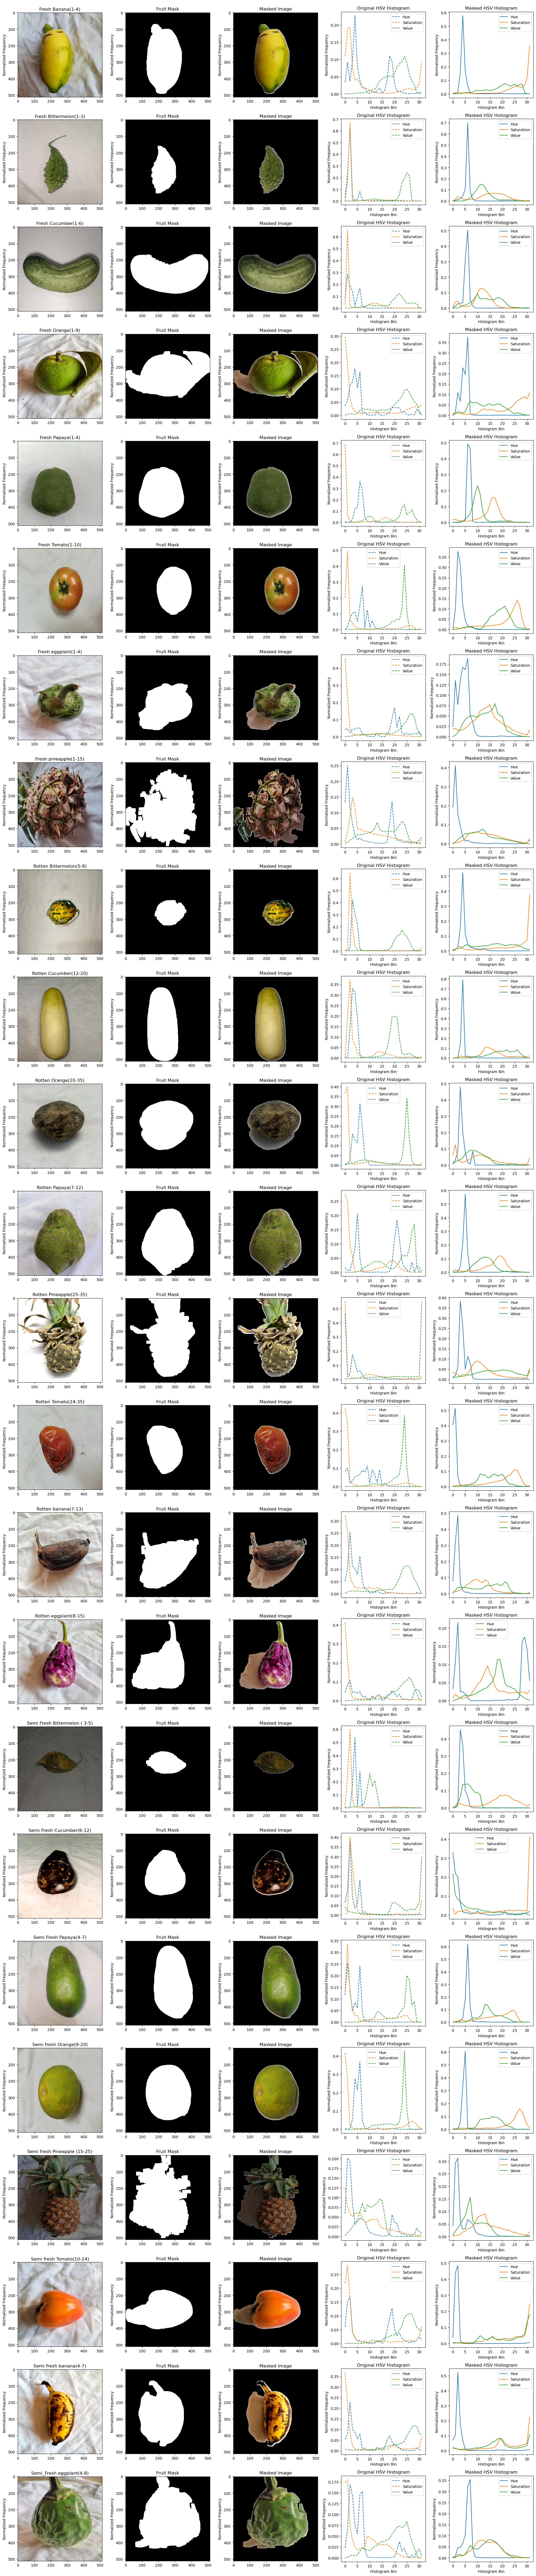

In [29]:
# Get one random image from each original class
selected_paths = []
selected_labels = []

for label in np.unique(train_labels):

    indices = np.where(train_labels == label)[0]
    idx = np.random.choice(indices)

    selected_paths.append(train_paths[idx])

    # Map numerical label to original folder name
    selected_labels.append(dataset.classes[label])

visualize_hsv_features(selected_paths, selected_labels)

In [10]:
def plot_average_hsv_histograms(X, y, class_names):

    fig, axes = plt.subplots(1, 3, figsize=(20, 6))

    channels = [
        ("Hue", 0, 32),
        ("Saturation", 32, 64),
        ("Value", 64, 96)
    ]

    for class_label in np.unique(y):

        class_features = X[np.array(y) == class_label]

        for ax, (channel, start, end) in zip(axes, channels):

            features = class_features[:, start:end]

            mean = features.mean(axis=0)

            ax.plot(
                np.arange(32),
                mean,
                label=class_names[class_label]
            )

            ax.set_title(f"Average {channel} Distribution")
            ax.set_xlabel("Histogram Bin")
            ax.set_ylabel("Normalized Frequency")

    for ax in axes:
        ax.legend(fontsize=7, bbox_to_anchor=(1.05, 1), loc="upper left")

    plt.tight_layout()
    plt.show()

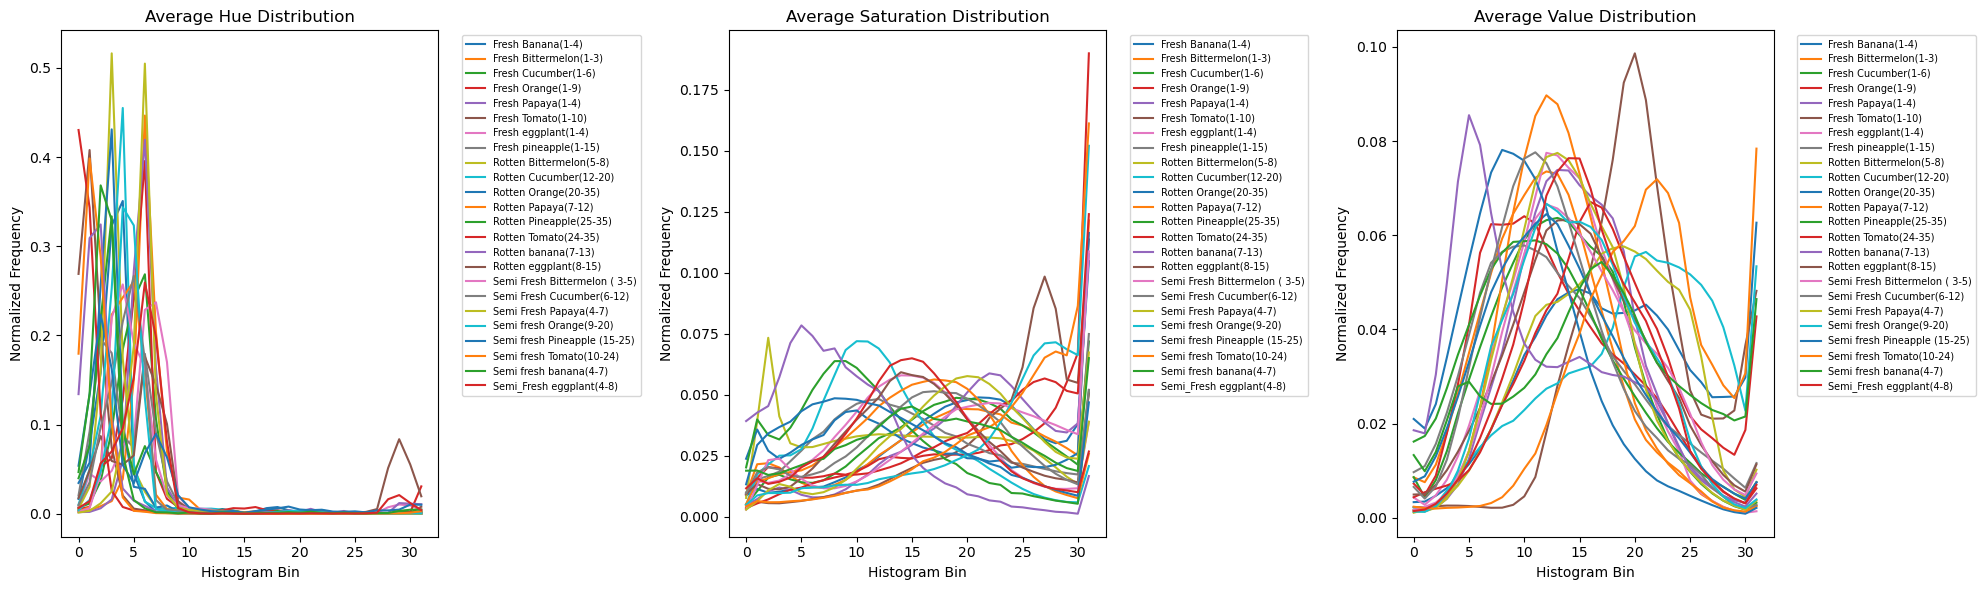

In [11]:
plot_average_hsv_histograms(X_train, y_train, class_names)

In [12]:
# Standardize HSV features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

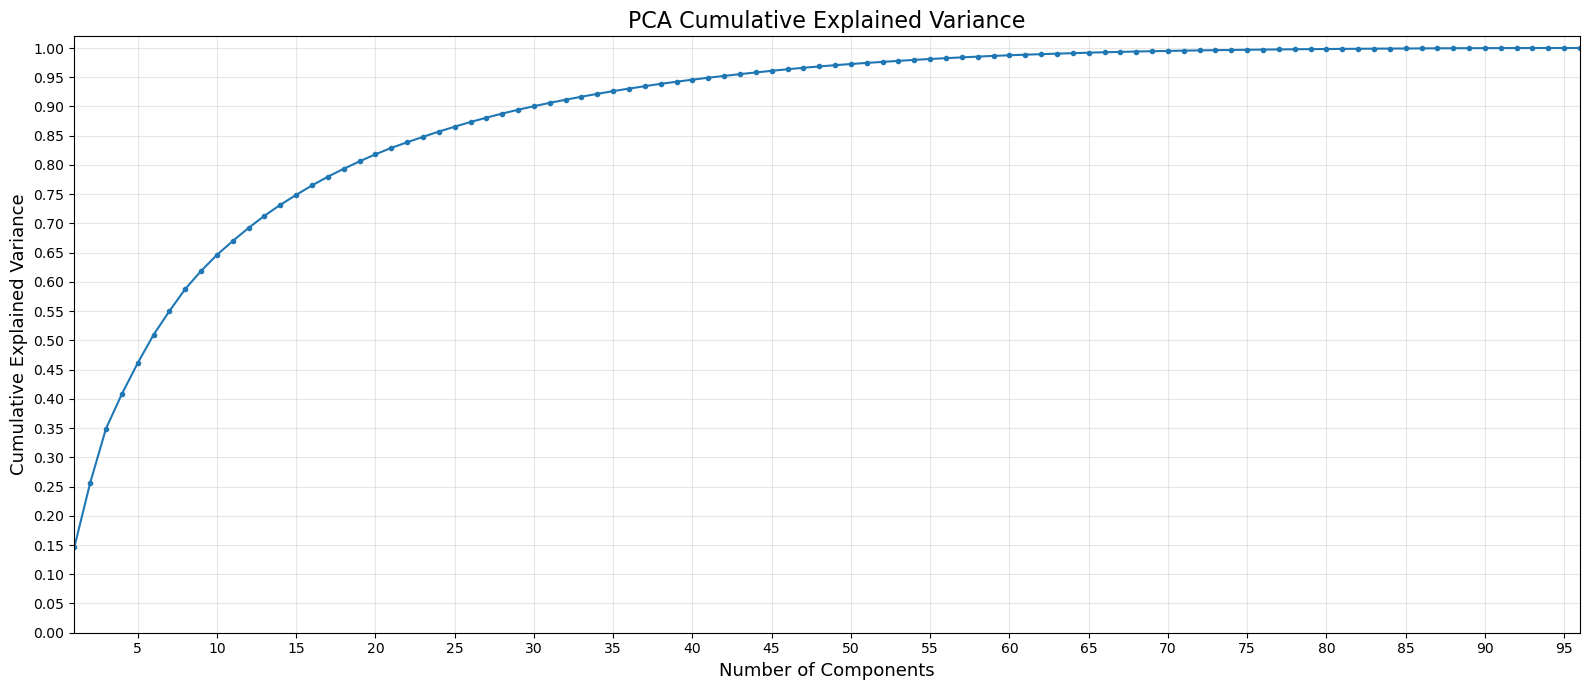

In [13]:
pca = PCA()

X_train_pca = pca.fit_transform(X_train_scaled)

cumulative_variance = np.cumsum(
    pca.explained_variance_ratio_
)

plt.figure(figsize=(16, 7))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker='o',
    markersize=3
)

plt.xlabel("Number of Components", fontsize=13)
plt.ylabel("Cumulative Explained Variance", fontsize=13)
plt.title("PCA Cumulative Explained Variance", fontsize=16)

plt.xticks(range(0, 97, 5))
plt.yticks(np.arange(0, 1.05, 0.05))

plt.grid(True, alpha=0.3)
plt.xlim(1, 96)
plt.ylim(0, 1.02)

plt.tight_layout()
plt.show()

In [14]:
# Standardize HSV features
scaler = StandardScaler()

X_train_hsv_scaled = scaler.fit_transform(X_train)

# Reduce to 30 dimensions
pca = PCA(n_components=30)

X_train_hsv_pca = pca.fit_transform(X_train_hsv_scaled)

# Calculate explained variance
explained_variance = pca.explained_variance_ratio_

print("PCA Shape:", X_train_pca.shape)
print("Explained variance:", explained_variance)
print("Total explained variance:", explained_variance.sum())

PCA Shape: (9912, 96)
Explained variance: [0.1458093  0.110131   0.09315142 0.05907982 0.05284547 0.04848563
 0.04048899 0.03785513 0.03089671 0.02754258 0.02363343 0.02247431
 0.02072977 0.01869476 0.01700257 0.0161957  0.01495179 0.01349556
 0.01268215 0.01202025 0.01106221 0.00954069 0.0093131  0.00903542
 0.00829232 0.00808406 0.00728415 0.00716301 0.00645335 0.00608525]
Total explained variance: 0.9004799


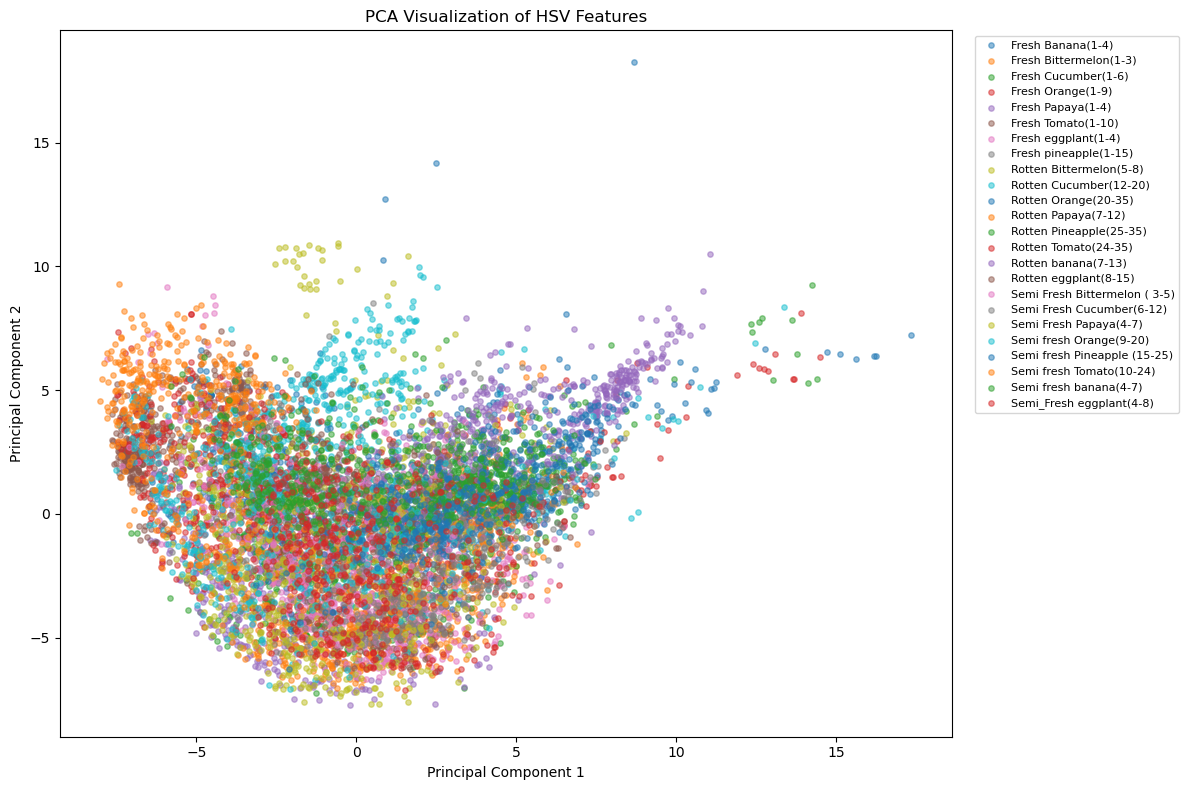

In [15]:
plt.figure(figsize=(12, 8))

for label in np.unique(y_train):
    indices = y_train == label

    plt.scatter(
        X_train_hsv_pca[indices, 0],
        X_train_hsv_pca[indices, 1],
        label=dataset.classes[label],
        alpha=0.5,
        s=15
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of HSV Features")

# Move legend outside the plot
plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=8
)

plt.tight_layout()
plt.show()

In [16]:
# Reduce standardized HSV features from 96 to 30 dimensions
pca_tsne = PCA(n_components=30, random_state=34)

X_train_pca_30 = pca_tsne.fit_transform(X_train_hsv_scaled)

print("Original shape:", X_train_hsv_scaled.shape)
print("PCA shape:", X_train_pca_30.shape)

# Apply t-SNE to standardized HSV features
tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate='auto',
    init='pca',
    random_state=34
)

X_train_hsv_tsne = tsne.fit_transform(X_train_pca_30)

Original shape: (9912, 96)
PCA shape: (9912, 30)


In [17]:
freshness_labels = []

for label in train_labels:

    class_name = dataset.classes[int(label)].lower()

    if "semi" in class_name:
        freshness_labels.append("Semi-Fresh")

    elif "rotten" in class_name:
        freshness_labels.append("Rotten")

    else:
        freshness_labels.append("Fresh")

freshness_labels = np.array(freshness_labels)

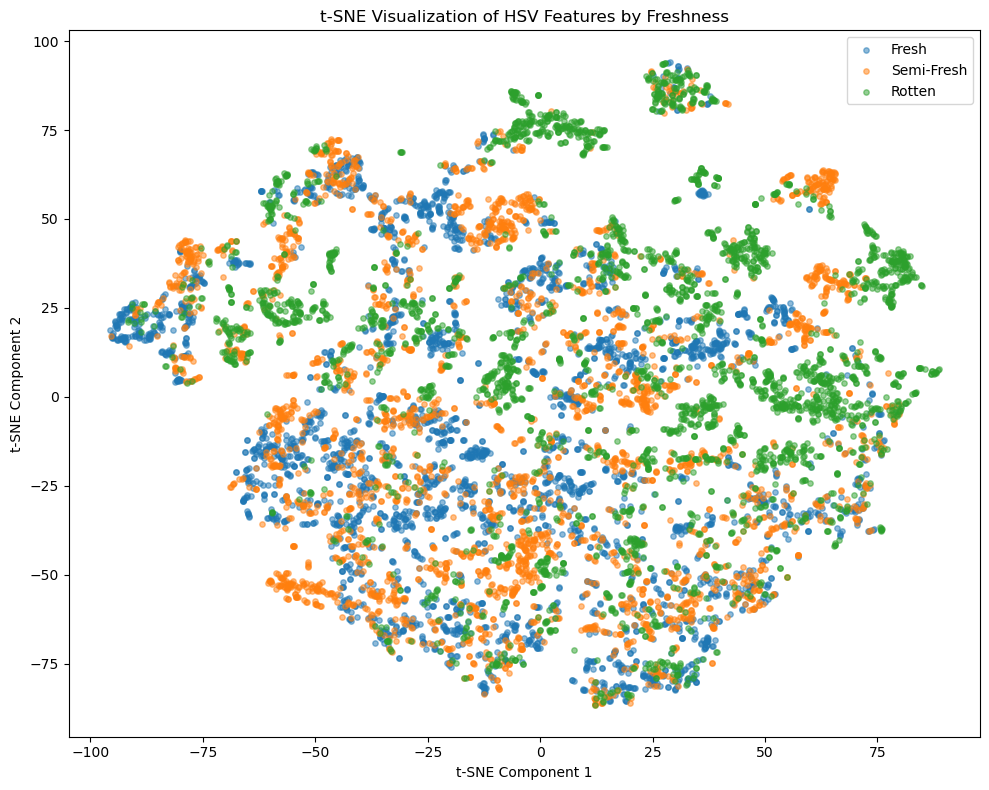

In [18]:

plt.figure(figsize=(10, 8))

for category in ["Fresh", "Semi-Fresh", "Rotten"]:

    indices = freshness_labels == category

    plt.scatter(
        X_train_hsv_tsne[indices, 0],
        X_train_hsv_tsne[indices, 1],
        label=category,
        alpha=0.5,
        s=15
    )

plt.title("t-SNE Visualization of HSV Features by Freshness")
plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")

plt.legend()
plt.tight_layout()
plt.show()


1. Create Laplacian Kernel 
3. Apply to images to get feature vector
4. Visualize a example of each (fruit x freshness)
5. Visualize the distribution across the dataset
6. PCA
7. TSNE

In [30]:
def apply_laplacian_pipeline(image_path):

    image = cv2.imread(image_path)

    # Create fruit mask
    mask = create_fruit_mask(
        image
    )

    # Grayscale  + Gaussian blur
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    gray = cv2.GaussianBlur(gray, (3, 3), 0) 

    # 8-neighbor Laplacian kernel
    kernel = np.array([
    [-0.5, -1.0, -0.5],
    [-1.0,  6.0, -1.0],
    [-0.5, -1.0, -0.5]
    ], dtype=np.float32)

    # Apply convolution
    laplacian = cv2.filter2D(
        gray.astype(np.float32),
        cv2.CV_32F,
        kernel
    )

    # Keep only fruit-region responses
    masked_laplacian = np.where(
        mask > 0,
        laplacian,
        0
    )

    return masked_laplacian, mask

In [ ]:
def extract_laplacian_features(image_path):
    masked_laplacian, mask = apply_laplacian_pipeline(image_path)

    # Drop the mask border 
    inner = cv2.erode((mask > 0).astype(np.uint8), np.ones((5, 5), np.uint8)) > 0
    if inner.sum() < 50:                      # failed mask, avoid NaNs / percentile errors
        return np.zeros(9, dtype=np.float32)

    fruit_responses = masked_laplacian[inner]
    abs_values = np.abs(fruit_responses)

    features = [
        np.mean(abs_values),
        np.std(fruit_responses),
        np.mean(fruit_responses ** 2),
        np.median(abs_values),
        np.percentile(abs_values, 25),
        np.percentile(abs_values, 75),
        np.percentile(abs_values, 90),
        np.percentile(abs_values, 95),
        np.percentile(abs_values, 99)
    ]
    return np.array(features, dtype=np.float32)

In [32]:
# Extract training features
X_train_laplacian = np.array([
    extract_laplacian_features(path)
    for path in train_paths
])

# Extract validation features
X_val_laplacian = np.array([
    extract_laplacian_features(path)
    for path in val_paths
])

# Extract test features
X_test_laplacian = np.array([
    extract_laplacian_features(path)
    for path in test_paths
])

In [33]:
print("Training:", X_train_laplacian.shape)
print("Validation:", X_val_laplacian.shape)
print("Test:", X_test_laplacian.shape)

Training: (9912, 9)
Validation: (2124, 9)
Test: (2124, 9)


In [34]:
X_train_laplacian = np.stack([extract_laplacian_features(p) for p in train_paths])
X_val_laplacian   = np.stack([extract_laplacian_features(p) for p in val_paths])
X_test_laplacian  = np.stack([extract_laplacian_features(p) for p in test_paths])

In [35]:

scaler_laplacian = StandardScaler()

X_train_scaled_laplacian = scaler_laplacian.fit_transform(X_train_laplacian)
X_val_scaled_laplacian = scaler_laplacian.transform(X_val_laplacian)
X_test_scaled_laplacian = scaler_laplacian.transform(X_test_laplacian)

In [36]:

pca_laplacian = PCA(n_components=2)

X_train_pca_laplacian = pca_laplacian.fit_transform(
    X_train_scaled_laplacian
)

X_val_pca_laplacian = pca_laplacian.transform(
    X_val_scaled_laplacian
)

X_test_pca_laplacian = pca_laplacian.transform(
    X_test_scaled_laplacian
)

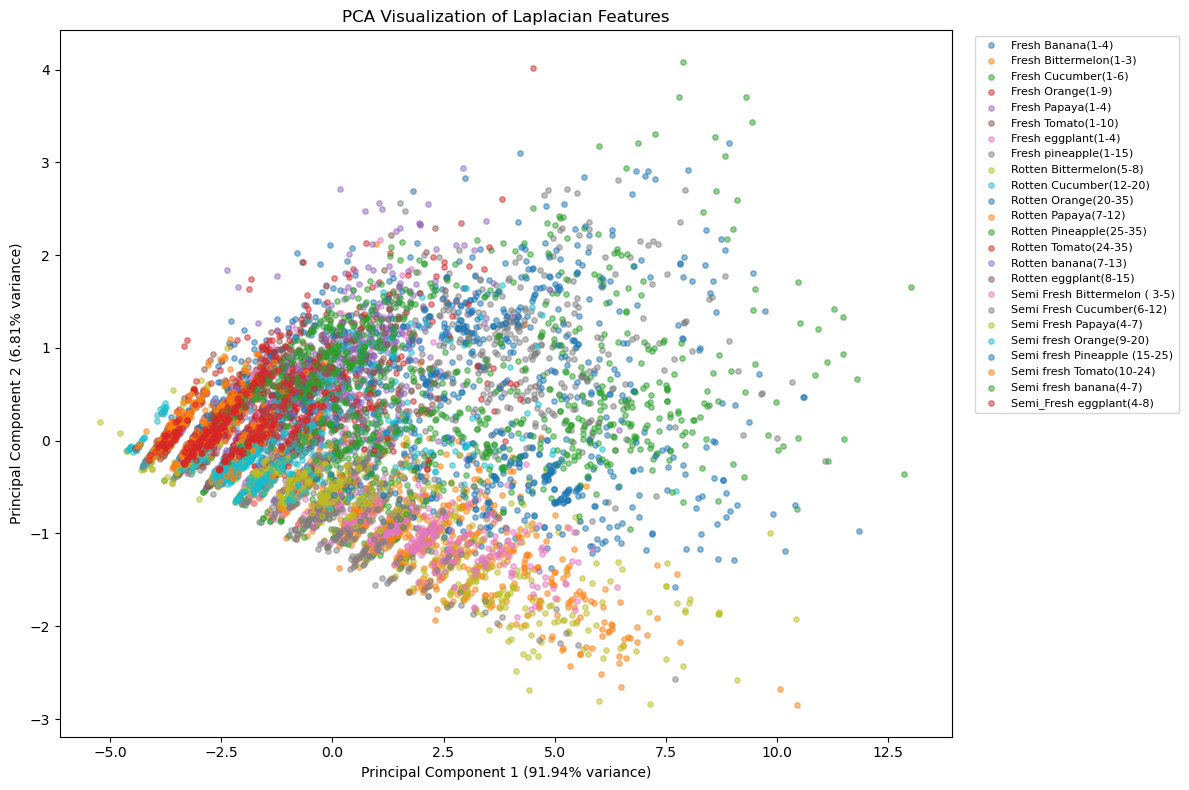

In [37]:
plt.figure(figsize=(12, 8))

for label in np.unique(train_labels):
    indices = train_labels == label

    plt.scatter(
        X_train_pca_laplacian[indices, 0],
        X_train_pca_laplacian[indices, 1],
        label=dataset.classes[int(label)],
        alpha=0.5,
        s=15
    )

plt.xlabel(
    f"Principal Component 1 ({pca_laplacian.explained_variance_ratio_[0]*100:.2f}% variance)"
)

plt.ylabel(
    f"Principal Component 2 ({pca_laplacian.explained_variance_ratio_[1]*100:.2f}% variance)"
)

plt.title("PCA Visualization of Laplacian Features")

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=8
)

plt.tight_layout()
plt.show()

In [38]:

tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    random_state=42
)

X_train_laplacian_tsne = tsne.fit_transform(X_train_scaled_laplacian)

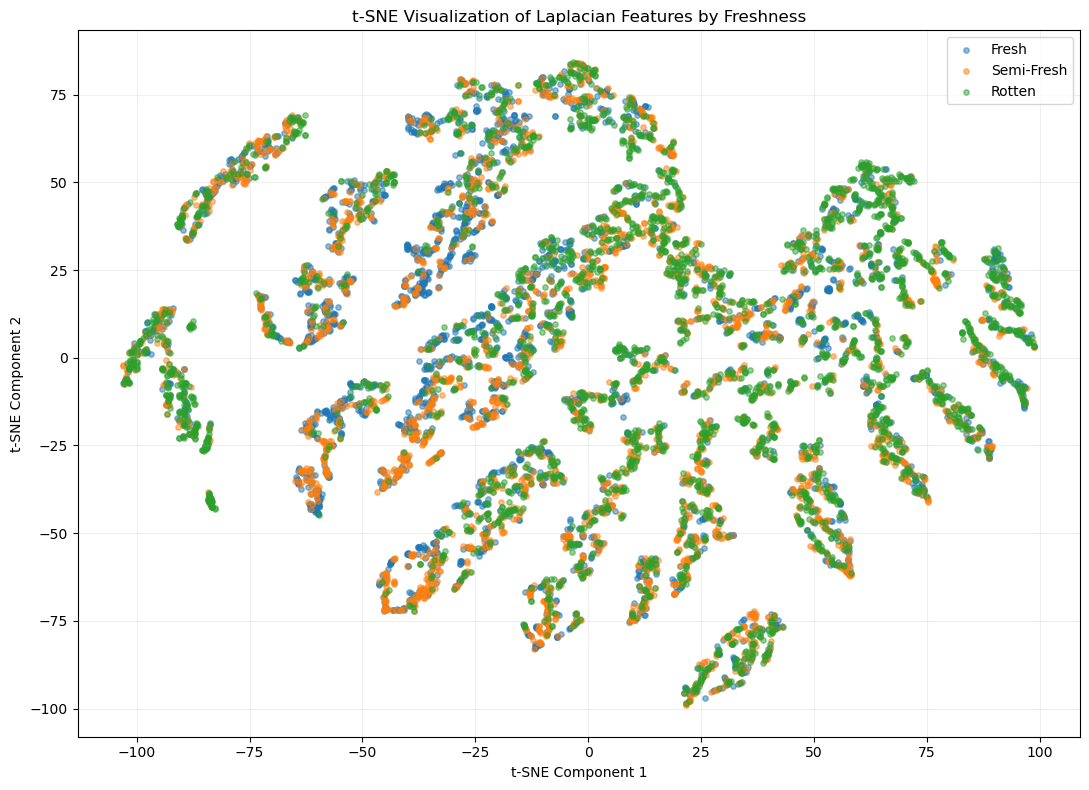

In [39]:
plt.figure(figsize=(11, 8))

for category in ["Fresh", "Semi-Fresh", "Rotten"]:

    indices = freshness_labels == category

    plt.scatter(
        X_train_laplacian_tsne[indices, 0],
        X_train_laplacian_tsne[indices, 1],
        label=category,
        alpha=0.5,
        s=15
    )

plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.title("t-SNE Visualization of Laplacian Features by Freshness")

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()